# MFPCA i FPCA clàssica quan el domini és comú

Autor: Leonel Fernando Nabaza Ruibal

**Pregunta:** Què passa quan apliquem el mètode de Happ & Greven (2018) per a MFPCA
i el domini paramètric de totes les variables funcionals és el mateix? Hi ha alguna
relació amb la FPCA "clàssica" (Ramsay & Silverman, 2005; Berrendero et al., 2011)?

Aquest notebook ho comprova de manera empírica amb el paquet **FDApy** (Golovkine, 2021),
que implementa Happ & Greven (2018).

Instal·lació (si cal):
```bash
pip install FDApy
```


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA

np.random.seed(123)


---
# Part 1 — Plantejament teòric

Considerem $p=2$ variables funcionals $X^{(1)}, X^{(2)}$ definides sobre el **mateix**
domini $T$. El producte escalar multivariant que defineix Happ & Greven (2018, Sec. 2.1)
és

$$
\langle X, Y \rangle_{\mathcal H} \;=\; \sum_{j=1}^{2} \int_T X^{(j)}(t)\, Y^{(j)}(t)\, dt .
$$

L'operador de covariància associat, $\Gamma$, actua com

$$
(\Gamma f)^{(j)}(t) \;=\; \sum_{j'=1}^{2} \int_T C_{jj'}(t,t')\, f^{(j')}(t')\, dt',
\qquad C_{jj'}(t,t') = \mathrm{Cov}\big(X^{(j)}(t), X^{(j')}(t')\big).
$$

**Quan el domini és comú**, aquest operador ja no necessita l'aparell general
d'espais de Hilbert de dimensions diferents que Happ & Greven introdueixen per al cas
de dominis heterogenis: $\Gamma$ esdevé simplement un operador integral amb nucli
$p\times p$ definit positiu $C(s,t)$, sobre $T\times T$. Els mateixos autors ho diuen
explícitament (Happ & Greven, 2018, Sec. 2.2, p. 653): la diferència amb els mètodes
existents *"for data with elements observed on the same (one-dimensional) domain"*
és que, en aquest cas especial, $T$ ja és un operador integral amb nucli definit
positiu — exactament el marc de la FPCA multivariant "clàssica"
(Ramsay & Silverman, 2005, cap. 8; Berrendero et al., 2011; Saporta, 1981).

## El truc de la concatenació

Podem comprovar-ho de manera constructiva. Si $T=[0,L]$, definim la funció
"concatenada" $Z$ sobre el domini doble $[0,2L]$:

$$
Z(t) \;=\;
\begin{cases}
X^{(1)}(t), & t\in[0,L] \\[2pt]
X^{(2)}(t-L), & t\in[L,2L]
\end{cases}
$$

Aleshores

$$
\int_0^{2L} Z(t)\,W(t)\,dt
= \int_0^L X^{(1)}(t) Y^{(1)}(t)\,dt + \int_0^L X^{(2)}(t) Y^{(2)}(t)\,dt
= \langle X, Y\rangle_{\mathcal H}.
$$

És a dir: **el producte escalar multivariant amb domini comú i pesos $w_j=1$ és,
literalment, el producte escalar $L^2$ ordinari de la corba concatenada $Z$.**
Com que la MFPCA es defineix únicament a partir d'aquest producte escalar
(diagonalització de l'operador de covariància), n'hi ha prou amb aquest fet per
concloure que:

- els **valors propis** de la MFPCA i de la FPCA univariant de $Z$ han de coincidir,
- les **autofuncions** de la MFPCA, partides en els dos trossos $[0,L]$ i $[L,2L]$,
  han de coincidir (llevat de signe) amb les autofuncions de $Z$,
- els **scores** (puntuacions) han de coincidir (llevat de signe).

Ho comprovem a continuació amb dades simulades.


---
# Part 2 — Simulació de dades sobre un domini comú

Generem $n$ individus amb dues variables funcionals $X^{(1)}(t), X^{(2)}(t)$ sobre el
mateix domini $t\in[0,1]$, però amb una estructura de covariància més rica que un sol
mode, per poder comparar diverses components a la vegada:

$$
X^{(j)}(t) \;=\; \sum_{m=0}^{M-1} \xi_{i,m}\, b^{(j)}_m(t) \;+\; \varepsilon^{(j)}(t),
\qquad j=1,2,
$$

on:

- $\xi_{i,m} \sim N(0,\lambda_m)$ són els **mateixos** "scores" latents per a totes
  dues variables (això és el que fa que $X^{(1)}$ i $X^{(2)}$ estiguin correlacionades),
- $b^{(1)}_m$ són funcions de la base de Fourier real,
- $b^{(2)}_m$ són les mateixes funcions de base però desplaçades i reescalades
  (una "forma" diferent, però generada pels mateixos scores),
- $\varepsilon^{(j)}(t)$ és soroll blanc gaussià petit afegit a la graella.


In [2]:
t = np.linspace(0, 1, 101)
argvals = DenseArgvals({'input_dim_0': t})


def fourier_basis(t, m):
    '''Base de Fourier real: m=0 constant, m senar sinus, m parell cosinus.'''
    if m == 0:
        return np.ones_like(t)
    k = (m + 1) // 2
    return np.sqrt(2) * (np.sin(2 * np.pi * k * t) if m % 2 else np.cos(2 * np.pi * k * t))


M = 6          # nombre de components "veritables" del model generador
n = 150        # nombre d'individus

lambdas = np.array([4.0, 2.0, 1.0, 0.5, 0.25, 0.1])       # variancies veritables
scores_true = np.random.normal(size=(n, M)) * np.sqrt(lambdas)

Phi = np.stack([fourier_basis(t, m) for m in range(M)], axis=0)   # base de X1
Psi = np.roll(Phi, shift=7, axis=1) * 0.8                         # base de X2 (mateixos scores!)

X1 = scores_true @ Phi + 0.05 * np.random.randn(n, len(t))
X2 = scores_true @ Psi + 0.05 * np.random.randn(n, len(t))


## Construcció dels objectes funcionals

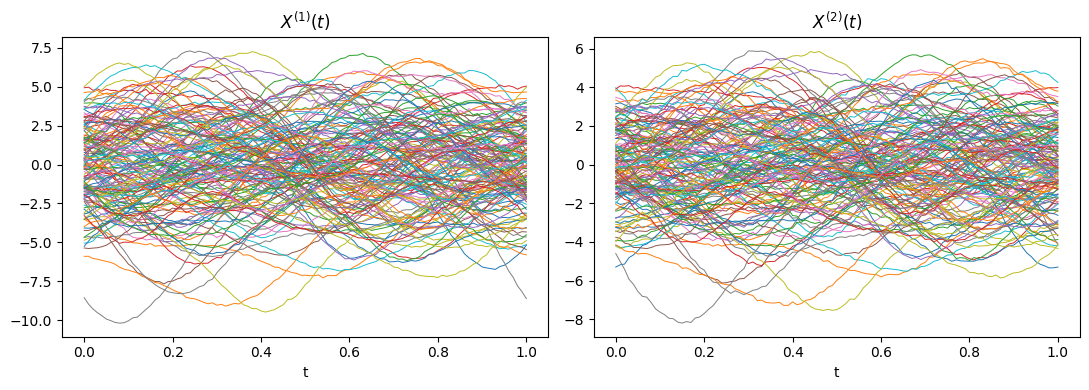

In [3]:
fd1 = DenseFunctionalData(argvals, DenseValues(X1))
fd2 = DenseFunctionalData(argvals, DenseValues(X2))
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, X1.T, linewidth=0.7)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(t, X2.T, linewidth=0.7)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


---
# Part 3 — (A) MFPCA de Happ & Greven

Ajustem la MFPCA de la manera habitual: expansió univariant per a cada element i,
després, PCA clàssica sobre els coeficients concatenats. Aquí fem servir `UFPCA`
(FPCA univariant) com a mètode d'expansió per a cada element, perquè és precisament
amb la FPCA univariant amb qui volem comparar el resultat.


In [4]:
K = 4  # nombre de components multivariades a estimar

uniExpansions = [
    {'method': 'UFPCA', 'n_components': 10},
    {'method': 'UFPCA', 'n_components': 10},
]

mfpca1 = MFPCA(n_components=K, method='covariance', univariate_expansions=uniExpansions)
mfpca1.fit(mData)

scores_mfpca = mfpca1.transform(mData)

print("Valors propis (MFPCA):")
print(np.round(mfpca1.eigenvalues, 4))


Valors propis (MFPCA):
[5.9828 3.5983 1.7299 0.6253]


---
# Part 4 — (B) FPCA "clàssica" via concatenació

Seguint la Part 1, construïm la corba concatenada $Z(t)$ ajuntant $X^{(1)}$ i $X^{(2)}$
sobre un domini doble $[0,2]$, i li apliquem una FPCA univariant estàndard (`UFPCA`).


In [5]:
delta = t[1] - t[0]
t_concat = np.concatenate([t, t + t[-1] + delta])          # domini [0, 2] contigu
argvals_concat = DenseArgvals({'input_dim_0': t_concat})
X_concat = np.concatenate([X1, X2], axis=1)

fd_concat = DenseFunctionalData(argvals_concat, DenseValues(X_concat))

ufpca1 = UFPCA(n_components=K, method='covariance')
ufpca1.fit(fd_concat)

scores_ufpca = ufpca1.transform(fd_concat)

print("Valors propis (FPCA clàssica, concatenació):")
print(np.round(ufpca1.eigenvalues, 4))


Valors propis (FPCA clàssica, concatenació):
[6.0107 3.6008 1.7481 0.6276]


---
# Part 5 — Comparació numèrica

Si la relació teòrica de la Part 1 és correcta, els valors propis han de ser
(pràcticament) idèntics i els scores han d'estar perfectament correlacionats
(amb possible canvi de signe, ja que el signe d'una autofunció no està determinat).


In [6]:
print("Valors propis MFPCA        :", np.round(mfpca1.eigenvalues, 4))
print("Valors propis FPCA clàssica :", np.round(ufpca1.eigenvalues, 4))
print("Diferència relativa         :",
      np.round(np.abs(mfpca1.eigenvalues - ufpca1.eigenvalues) / ufpca1.eigenvalues, 4))

print("\nCorrelació entre scores (ha de ser ≈ ±1):")
for k in range(K):
    corr = np.corrcoef(scores_mfpca[:, k], scores_ufpca[:, k])[0, 1]
    print(f"  Component {k+1}: {corr:.4f}")


Valors propis MFPCA        : [5.9828 3.5983 1.7299 0.6253]
Valors propis FPCA clàssica : [6.0107 3.6008 1.7481 0.6276]
Diferència relativa         : [0.0047 0.0007 0.0104 0.0037]

Correlació entre scores (ha de ser ≈ ±1):
  Component 1: -1.0000
  Component 2: 1.0000
  Component 3: -1.0000
  Component 4: 1.0000


---
# Part 6 — Comparació visual de les autofuncions

Partim l'autofunció de $Z$ per la meitat del domini (posició $t=1$) i la comparem
amb les dues parts de la primera autofunció multivariant de la MFPCA
($X^{(1)}$ i $X^{(2)}$ per separat).


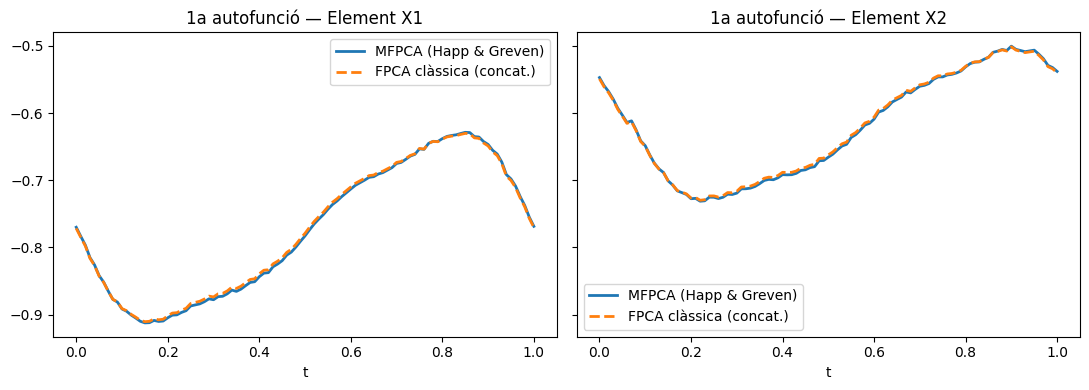

In [7]:
ef_mfpca_X1 = mfpca1.eigenfunctions.data[0].to_grid()
ef_mfpca_X2 = mfpca1.eigenfunctions.data[1].to_grid()
ef_ufpca    = ufpca1.eigenfunctions   # ja en graella

n_t = len(t)
ef_classic_X1 = ef_ufpca.values[:, :n_t]
ef_classic_X2 = ef_ufpca.values[:, n_t:]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ef_m, ef_c, titol in zip(
    axes,
    [ef_mfpca_X1.values, ef_mfpca_X2.values],
    [ef_classic_X1, ef_classic_X2],
    ["Element X1", "Element X2"],
):
    signe = np.sign(np.corrcoef(ef_m[0], ef_c[0])[0, 1])
    ax.plot(t, ef_m[0], label="MFPCA (Happ & Greven)", lw=2)
    ax.plot(t, signe * ef_c[0], "--", label="FPCA clàssica (concat.)", lw=2)
    ax.set_title(f"1a autofunció — {titol}")
    ax.set_xlabel("t")
    ax.legend()

plt.tight_layout()
plt.show()


---
# Conclusió

Quan totes les variables funcionals comparteixen el mateix domini, la MFPCA de
Happ & Greven (2018) i la FPCA "clàssica" (Ramsay & Silverman, 2005; Berrendero
et al., 2011) donen **els mateixos valors propis, les mateixes autofuncions
(llevat de signe) i els mateixos scores**. Les petites diferències numèriques que
s'observen provenen únicament del truncament de l'expansió univariant intermèdia
(aquí, 10 components de UFPCA per element), no d'una diferència teòrica real.

Això confirma el que anticipa el mateix article de Happ & Greven (Sec. 2.2, p. 653):
el seu marc general **es redueix exactament al cas clàssic** quan els dominis
coincideixen — el cas de dominis diferents és la vertadera generalització que aporta
el mètode.
